In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks

FS_HZ = 250  # sampling rate: 250 samples per second


def make_ecg(duration_s=30, heart_rate_bpm=72):
    t_s = np.arange(0, duration_s, 1 / FS_HZ)
    rr_s = 60 / heart_rate_bpm
    true_peaks_s = np.arange(rr_s / 2, duration_s - 0.5, rr_s)

    ecg_mv = np.zeros_like(t_s)
    for p in true_peaks_s:
        ecg_mv += np.exp(-0.5 * ((t_s - p) / 0.012) ** 2)

    drift_mv = 0.5 * np.sin(2 * np.pi * 0.3 * t_s)
    mains_mv = 0.1 * np.sin(2 * np.pi * 50 * t_s)
    noise_mv = np.random.default_rng(0).normal(0, 0.03, len(t_s))
    return t_s, ecg_mv + drift_mv + mains_mv + noise_mv, true_peaks_s


def bandpass(signal_mv, low_hz=0.5, high_hz=30):
    b, a = butter(4, [low_hz, high_hz], btype="bandpass", fs=FS_HZ)
    return filtfilt(b, a, signal_mv)


def find_r_peaks(filtered_mv):
    peaks, _ = find_peaks(filtered_mv, height=0.5, distance=int(0.3 * FS_HZ))
    return peaks


def heart_rate_bpm(peaks):
    rr_s = np.diff(peaks) / FS_HZ
    return 60 / np.mean(rr_s)

True HR: 72 bpm | Estimated HR: 72.0 bpm


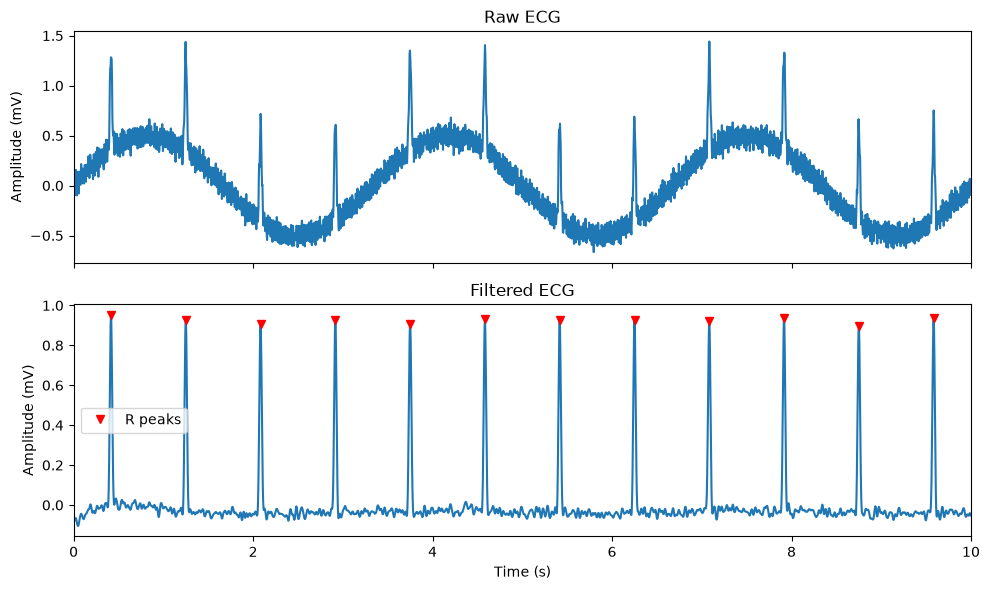

In [3]:
t_s, raw_mv, true_peaks_s = make_ecg(heart_rate_bpm=72)
filtered_mv = bandpass(raw_mv)
peaks = find_r_peaks(filtered_mv)
print("True HR: 72 bpm | Estimated HR:", round(heart_rate_bpm(peaks), 1), "bpm")

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
ax[0].plot(t_s, raw_mv)
ax[0].set_title("Raw ECG")
ax[1].plot(t_s, filtered_mv)
ax[1].plot(peaks / FS_HZ, filtered_mv[peaks], "rv", label="R peaks")
ax[1].set_title("Filtered ECG")
ax[1].legend()
for a in ax:
    a.set_ylabel("Amplitude (mV)")
ax[1].set_xlabel("Time (s)")
ax[1].set_xlim(0, 10)
plt.tight_layout()
plt.show()

In [4]:
for bpm in [72, 100]:
    _, ecg, true_peaks = make_ecg(heart_rate_bpm=bpm)
    peaks = find_r_peaks(bandpass(ecg))
    assert abs(heart_rate_bpm(peaks) - bpm) < 1
    assert len(peaks) == len(true_peaks)

t = np.arange(0, 10, 1 / FS_HZ)
out = bandpass(np.sin(2 * np.pi * 50 * t))
assert np.max(np.abs(out[500:-500])) < 0.1

print("All checks passed")

All checks passed
